In [1]:

print("SMS Spam Detection Project Started!")


SMS Spam Detection Project Started!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

import zipfile
import os

zip_path = "/content/sms+spam+collection.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/sms_dataset")

print("Dataset extracted successfully!")
print(os.listdir("/content/sms_dataset"))


Dataset extracted successfully!
['SMSSpamCollection', 'readme']


In [5]:

import pandas as pd
import os

folder = "/content/sms_dataset"
print("Extracted files:", os.listdir(folder))

file_path = os.path.join(folder, "SMSSpamCollection")

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("\nFirst five messages:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nSpam and ham counts:")
print(df["label"].value_counts())


Extracted files: ['SMSSpamCollection', 'readme']

First five messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Spam and ham counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:

df = df.dropna()
df = df.drop_duplicates().reset_index(drop=True)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " URL ", text)
    text = re.sub(r"\d+", " NUMBER ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

print(df[["label", "clean_message"]].head())


  label                                      clean_message
0   ham  go until jurong point crazy available only in ...
1   ham                            ok lar joking wif u oni
2  spam  free entry in a wkly comp to win fa cup final ...
3   ham        u dun say so early hor u c already then say
4   ham  nah i don t think he goes to usf he lives arou...


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_message"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])


Training samples: 4135
Testing samples: 1034
TF-IDF features: 5000


In [8]:

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42),
    "Naive Bayes": MultinomialNB()
}

results = []
predictions = {}

for name, model in models.items():
    start = time.perf_counter()

    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    runtime = time.perf_counter() - start
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Runtime (seconds)": runtime
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))


        Model  Accuracy  Precision  Recall  F1-score  Runtime (seconds)
Decision Tree    0.9594     0.8397  0.8397    0.8397             0.7272
          KNN    0.9159     1.0000  0.3359    0.5029             0.2787
          SVM    0.9826     0.9829  0.8779    0.9274             0.0219
  Naive Bayes    0.9691     1.0000  0.7557    0.8609             0.0304


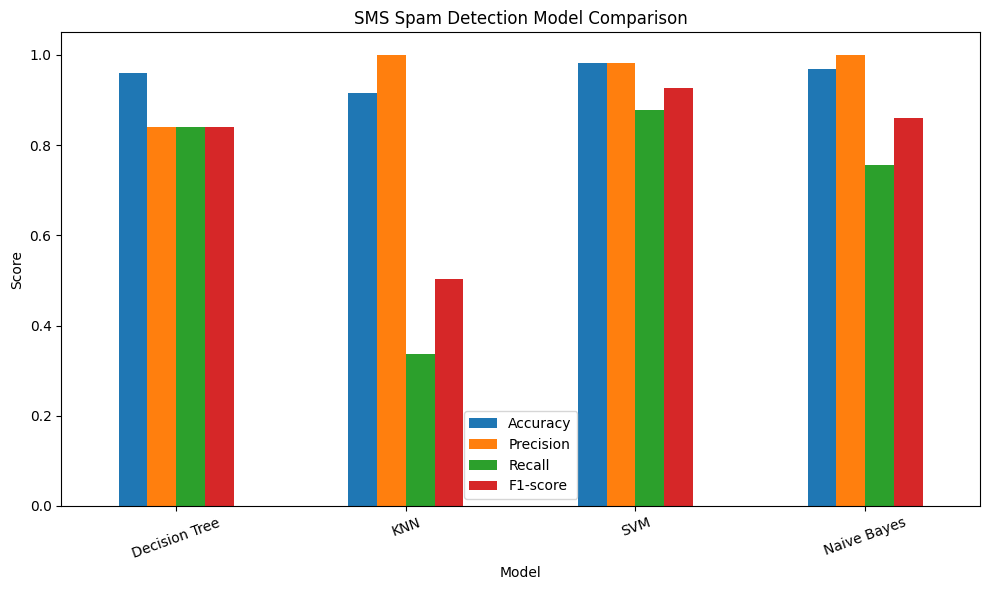

In [9]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("SMS Spam Detection Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


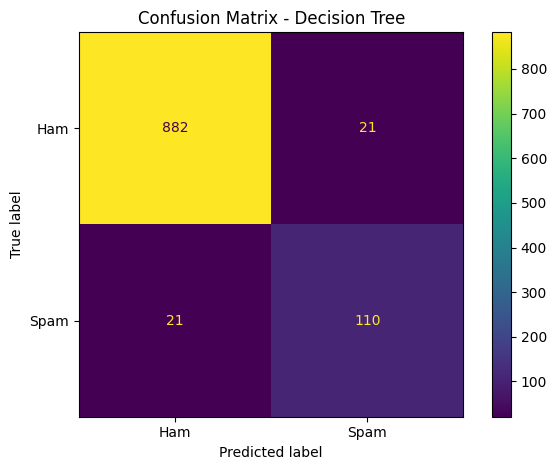

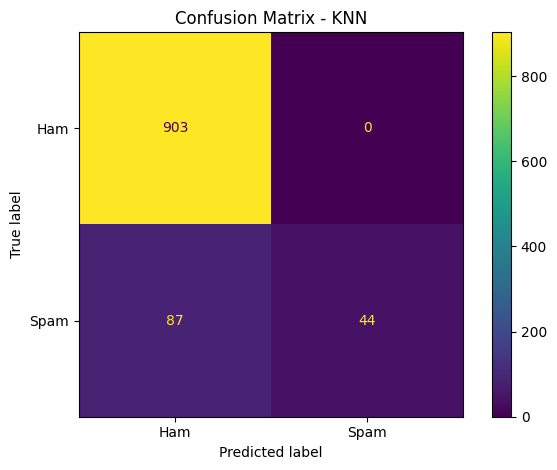

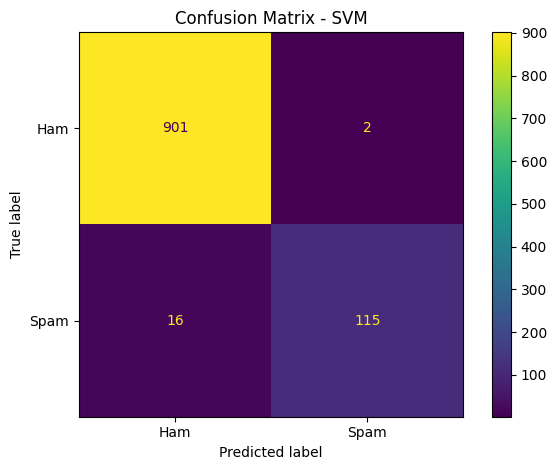

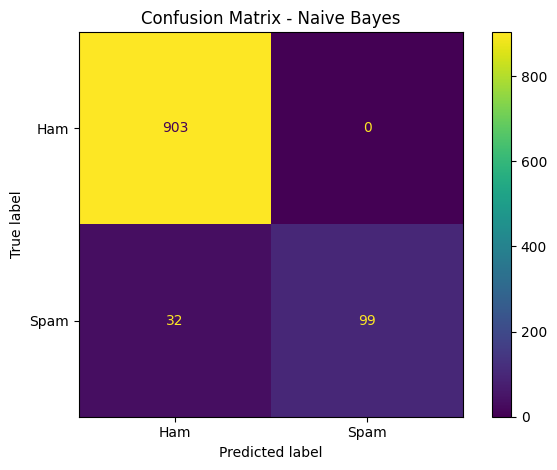

In [10]:

for name, y_pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


In [11]:

for k in [3, 5, 7, 9, 11]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_tfidf, y_train)

    pred = model.predict(X_test_tfidf)

    print(
        "K =", k,
        "| Accuracy =", round(accuracy_score(y_test, pred), 4),
        "| F1-score =", round(
            f1_score(y_test, pred, pos_label="spam"), 4
        )
    )


K = 3 | Accuracy = 0.9284 | F1-score = 0.6064
K = 5 | Accuracy = 0.9159 | F1-score = 0.5029
K = 7 | Accuracy = 0.8994 | F1-score = 0.3418
K = 9 | Accuracy = 0.8956 | F1-score = 0.2987
K = 11 | Accuracy = 0.8917 | F1-score = 0.2533


In [12]:

results_df.to_csv("model_comparison_results.csv", index=False)
print("Results saved successfully!")


Results saved successfully!


In [13]:

print(results_df.round(4).to_string(index=False))


        Model  Accuracy  Precision  Recall  F1-score  Runtime (seconds)
Decision Tree    0.9594     0.8397  0.8397    0.8397             0.7272
          KNN    0.9159     1.0000  0.3359    0.5029             0.2787
          SVM    0.9826     0.9829  0.8779    0.9274             0.0219
  Naive Bayes    0.9691     1.0000  0.7557    0.8609             0.0304


In [14]:

best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("Best model based on F1-score:")
print(best_model)


Best model based on F1-score:
Model                     SVM
Accuracy             0.982592
Precision            0.982906
Recall               0.877863
F1-score             0.927419
Runtime (seconds)    0.021909
Name: 2, dtype: object


In [15]:

knn_results = []

for k in [3, 5, 7, 9, 11]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, pos_label="spam", zero_division=0
        )
    })

knn_df = pd.DataFrame(knn_results)
print(knn_df.round(4).to_string(index=False))


 K  Accuracy  Precision  Recall  F1-score
 3    0.9284        1.0  0.4351    0.6064
 5    0.9159        1.0  0.3359    0.5029
 7    0.8994        1.0  0.2061    0.3418
 9    0.8956        1.0  0.1756    0.2987
11    0.8917        1.0  0.1450    0.2533


In [16]:

results_df.to_csv(
    "/content/model_comparison_results.csv", index=False
)

knn_df.to_csv(
    "/content/knn_what_if_results.csv", index=False
)

print("Both result files saved!")


Both result files saved!
